# Projeto final: surrogate e POD-NN para aerofólios

- estágio 1: rede que recebe os 12 CST, alpha e log10 Re e devolve cl, log10 cd e cm
- estágio 2: POD-NN que prevê a curva de Cp inteira (200 pontos). A SVD acha os modos e uma rede pequena aprende os 17 coeficientes
- os dois usam o mesmo split por aerofólio, e a NACA 2412 só entra no final

## Configuração

- no Colab monta o Drive e lê a pasta `Data Driven`
- fora do Colab procura a pasta `airfoil_db_v1_to_students` ao lado do script ou uma pasta acima
- dá pra trocar o caminho com a variável `DB`

In [1]:
import copy
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DB = Path('/content/drive/MyDrive/Data Driven')
except ImportError:
    try:
        AQUI = Path(__file__).resolve().parent
    except NameError:                       # rodando como notebook
        AQUI = Path.cwd()
    pasta = next((p for p in (AQUI, AQUI.parent) if (p / 'airfoil_db_v1_to_students').exists()), AQUI)
    DB = Path(os.environ.get('DB', pasta / 'airfoil_db_v1_to_students'))

torch.manual_seed(0)

## Dados e divisão

- as duas tabelas se ligam pelo `id`
- log10 de Re (entrada) e de Cd (saída)
- a NACA 2412 sai da base antes de tudo, e depois fica só espessura de 6% a 16%
- o split é por aerofólio (70/15/15), senão pontos do mesmo aerofólio ficam em conjuntos diferentes e o teste fica bom demais
- os aerofólios sintéticos são perturbações dos reais, então um sintético de teste pode ter o original no treino. O enunciado só pede separar por `id`, então fiz assim

In [2]:
airfoils = pd.read_csv(DB / 'airfoils.csv')
polars = pd.read_csv(DB / 'polars.csv')

# une pelo id
uni = pd.merge(polars, airfoils, on='id')

# log de Re e Cd
uni['LogRe'] = np.log10(uni['Re'])
uni['LogCd'] = np.log10(uni['Cd'])

# naca2412 vira o alvo e sai da base, depois filtra a espessura
target = uni[uni['name'] == 'naca2412']
assert len(target) > 0, 'naca2412 não está no airfoils.csv'
uni = uni[uni['name'] != 'naca2412']
uni = uni[(uni['t_max'] >= 0.06) & (uni['t_max'] <= 0.16)]

# split por aerofólio (todos os pontos de um id no mesmo conjunto)
rng = np.random.default_rng(30)
ids = rng.permutation(uni['id'].unique())

n = len(ids)
n_tr = int(n * 0.7)
n_v = int(n * 0.15)

ids_tr = ids[:n_tr]                  # primeiros 70%
ids_val = ids[n_tr:n_tr + n_v]       # de 70% a 85%
ids_te = ids[n_tr + n_v:]            # de 85% a 100%

treino = uni[uni['id'].isin(ids_tr)]
val = uni[uni['id'].isin(ids_val)]
teste = uni[uni['id'].isin(ids_te)]

print('Aerofólios treino/val/teste:', len(ids_tr), len(ids_val), len(ids_te))
print('Pontos treino/val/teste:', len(treino), len(val), len(teste))

Aerofólios treino/val/teste: 2171 465 466
Pontos treino/val/teste: 141697 30427 30163


## Estágio 1: preparação

- X tem 14 colunas (12 CST, alpha e log10 Re) e Y tem 3 (cl, log10 cd, cm)
- média e desvio só do treino, aplicados nos outros conjuntos (inclusive a NACA 2412)

In [3]:
X_columns = ['Au0', 'Au1', 'Au2', 'Au3', 'Au4', 'Au5',
             'Al0', 'Al1', 'Al2', 'Al3', 'Al4', 'Al5', 'alpha', 'LogRe']
Y_columns = ['Cl', 'LogCd', 'Cm']


def X_Y(df):
    X = df[X_columns].values.astype(np.float32)
    Y = df[Y_columns].values.astype(np.float32)
    return X, Y


def padroniza(X, Y, mx, sx, my, sy):
    return (X - mx) / sx, (Y - my) / sy


# estatísticas só do treino
X_tr, Y_tr = X_Y(treino)
mx_tr, sx_tr = X_tr.mean(axis=0), X_tr.std(axis=0)
my_tr, sy_tr = Y_tr.mean(axis=0), Y_tr.std(axis=0)
assert np.all(sx_tr > 0) and np.all(sy_tr > 0), 'coluna constante no treino'

X_tr, Y_tr = padroniza(X_tr, Y_tr, mx_tr, sx_tr, my_tr, sy_tr)
X_val, Y_val = padroniza(*X_Y(val), mx_tr, sx_tr, my_tr, sy_tr)
X_teste, Y_teste = padroniza(*X_Y(teste), mx_tr, sx_tr, my_tr, sy_tr)
X_target, Y_target = padroniza(*X_Y(target), mx_tr, sx_tr, my_tr, sy_tr)

# tensores
Entrada_treino, Saida_treino = torch.tensor(X_tr), torch.tensor(Y_tr)
Entrada_val, Saida_val = torch.tensor(X_val), torch.tensor(Y_val)
Entrada_teste = torch.tensor(X_teste)
Entrada_target = torch.tensor(X_target)

## Estágio 1: rede e treino

- 2 camadas ocultas de 64 neurônios com tanh e saída linear
- MSE, Adam e mini-lotes de 256
- early stopping: se a validação não melhora por 20 épocas, para e volta aos pesos da melhor época
- a função `treina` também serve pro estágio 2

In [4]:
def treina(rede, X, Y, Xv, Yv, lr=1e-3, batch=256, paciencia=20, max_epocas=500):
    # Adam + MSE + early stopping, devolve históricos, melhor época e melhor erro de validação
    loss_fn = nn.MSELoss()
    otimizador = torch.optim.Adam(rede.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, Y), batch_size=batch, shuffle=True)

    melhor_val = float('inf')        # melhor erro até agora
    contador = 0                     # épocas seguidas sem melhorar
    melhores_pesos = None
    hist_treino, hist_val = [], []

    for epoca in range(max_epocas):
        soma = 0
        for xb, yb in loader:
            loss = loss_fn(rede(xb), yb)
            otimizador.zero_grad()
            loss.backward()
            otimizador.step()
            soma += loss.item()
        hist_treino.append(soma / len(loader))

        with torch.no_grad():
            loss_val = loss_fn(rede(Xv), Yv).item()
        hist_val.append(loss_val)

        if loss_val < melhor_val:
            melhor_val = loss_val
            melhores_pesos = copy.deepcopy(rede.state_dict())
            contador = 0
        else:
            contador += 1
            if contador >= paciencia:
                print('Parou na época', epoca + 1)
                break

    rede.load_state_dict(melhores_pesos)
    return hist_treino, hist_val, int(np.argmin(hist_val)) + 1, melhor_val


rede = nn.Sequential(
    nn.Linear(14, 64),
    nn.Tanh(),
    nn.Linear(64, 64),
    nn.Tanh(),
    nn.Linear(64, 3)     # saída linear: Cl, LogCd e Cm
)

hist_treino, hist_val, melhor_epoca, melhor_val = treina(
    rede, Entrada_treino, Saida_treino, Entrada_val, Saida_val)
print('Melhor época:', melhor_epoca, '| erro de validação:', melhor_val)

Parou na época 156
Melhor época: 136 | erro de validação: 0.0037160541396588087


### Erros no teste

- RMSE de cl e cm em unidades reais
- no cd volto do log com `10**x` e calculo o erro relativo médio em %

In [5]:
with torch.no_grad():
    prev_teste = rede(Entrada_teste).numpy()          # padronizada

prev_teste_real = prev_teste * sy_tr + my_tr
Y_teste_real = Y_teste * sy_tr + my_tr

rmse_cl = np.sqrt(np.mean((prev_teste_real[:, 0] - Y_teste_real[:, 0]) ** 2))
rmse_cm = np.sqrt(np.mean((prev_teste_real[:, 2] - Y_teste_real[:, 2]) ** 2))
cd_prev = 10 ** prev_teste_real[:, 1]
cd_real = 10 ** Y_teste_real[:, 1]
erro_cd = np.mean(np.abs(cd_prev - cd_real) / cd_real) * 100

print('RMSE cl:', rmse_cl)
print('RMSE cm:', rmse_cm)
print('Erro médio cd (%):', erro_cd)

RMSE cl: 0.01269211
RMSE cm: 0.0020130964
Erro médio cd (%): 1.3021804


### NACA 2412 (nunca vista)

- rede contra XFOIL nos 4 Reynolds: curva de sustentação, polar de arrasto e momento

NACA 2412: RMSE cl = 0.0037 | erro cd = 0.48 %


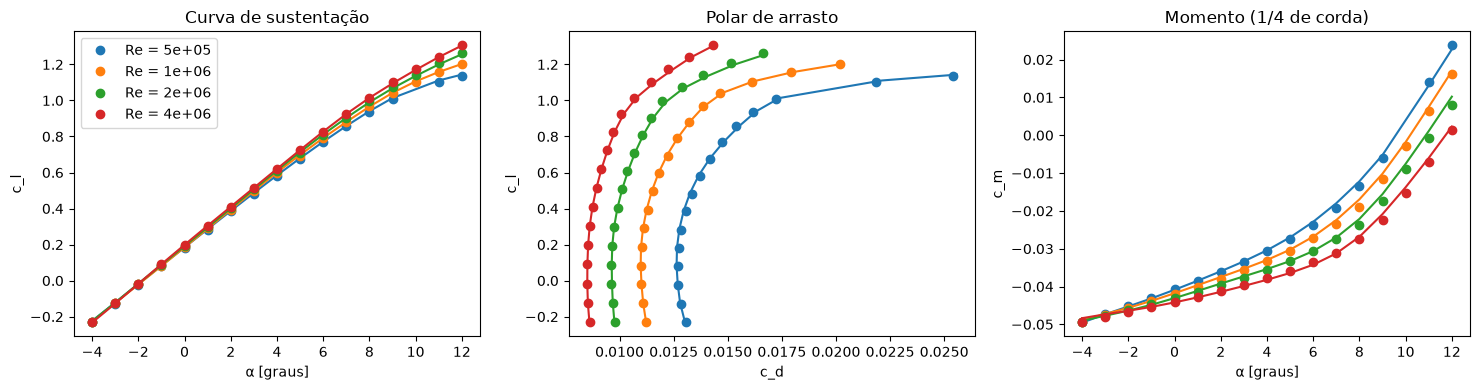

In [6]:
with torch.no_grad():
    prev_target = rede(Entrada_target).numpy()

alpha_na = target['alpha'].values
Re_na = target['Re'].values
prev_target_real = prev_target * sy_tr + my_tr
Y_target_real = Y_target * sy_tr + my_tr

rmse_cl_na = np.sqrt(np.mean((prev_target_real[:, 0] - Y_target_real[:, 0]) ** 2))
erro_cd_na = np.mean(np.abs(10 ** prev_target_real[:, 1] - 10 ** Y_target_real[:, 1])
                     / 10 ** Y_target_real[:, 1]) * 100
print(f'NACA 2412: RMSE cl = {rmse_cl_na:.4f} | erro cd = {erro_cd_na:.2f} %')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for Re_val in np.unique(Re_na):
    m = (Re_na == Re_val)
    ordem = np.argsort(alpha_na[m])          # ordena por alpha

    a = alpha_na[m][ordem]
    cl_x, cl_r = Y_target_real[m, 0][ordem], prev_target_real[m, 0][ordem]
    cm_x, cm_r = Y_target_real[m, 2][ordem], prev_target_real[m, 2][ordem]
    cd_x, cd_r = 10 ** Y_target_real[m, 1][ordem], 10 ** prev_target_real[m, 1][ordem]

    p = ax[0].plot(a, cl_x, 'o', label=f'Re = {Re_val:.0e}')
    cor = p[0].get_color()                   # mesma cor pro XFOIL e pra rede
    ax[0].plot(a, cl_r, '-', color=cor)
    ax[1].plot(cd_x, cl_x, 'o', color=cor)
    ax[1].plot(cd_r, cl_r, '-', color=cor)
    ax[2].plot(a, cm_x, 'o', color=cor)
    ax[2].plot(a, cm_r, '-', color=cor)

ax[0].set_xlabel('α [graus]'); ax[0].set_ylabel('c_l'); ax[0].set_title('Curva de sustentação')
ax[1].set_xlabel('c_d');       ax[1].set_ylabel('c_l'); ax[1].set_title('Polar de arrasto')
ax[2].set_xlabel('α [graus]'); ax[2].set_ylabel('c_m'); ax[2].set_title('Momento (1/4 de corda)')
ax[0].legend()
plt.tight_layout()
plt.show()

### Inclinação de cl e centro aerodinâmico

- faixa linear (|alpha| <= 4 graus), ajusto uma reta
- a inclinação sai em 1/grau, então multiplico por 180/pi pra ter 1/rad
- x_ac = 0,25 - dcm/dcl, e dcm/dcl é a inclinação de cm contra cl

In [7]:
for Re_val in np.unique(Re_na):
    m = (Re_na == Re_val)
    a = alpha_na[m]
    cl_x, cl_r = Y_target_real[m, 0], prev_target_real[m, 0]
    cm_x, cm_r = Y_target_real[m, 2], prev_target_real[m, 2]
    lin = np.abs(a) <= 4

    dcm_x = np.polyfit(cl_x[lin], cm_x[lin], 1)[0]
    dcm_r = np.polyfit(cl_r[lin], cm_r[lin], 1)[0]
    cla_x = np.polyfit(a[lin], cl_x[lin], 1)[0] * 180 / np.pi
    cla_r = np.polyfit(a[lin], cl_r[lin], 1)[0] * 180 / np.pi
    xac_x, xac_r = 0.25 - dcm_x, 0.25 - dcm_r

    print(f'Re = {Re_val:.0e} | c_lα XFOIL = {cla_x:.3f} | rede = {cla_r:.3f} '
          f'| diferença = {abs(cla_r - cla_x) / cla_x * 100:.2f} %')
    print(f'Re = {Re_val:.0e} | x_ac XFOIL = {xac_x:.4f} | rede = {xac_r:.4f}')

Re = 5e+05 | c_lα XFOIL = 5.821 | rede = 5.800 | diferença = 0.36 %
Re = 5e+05 | x_ac XFOIL = 0.2275 | rede = 0.2267
Re = 1e+06 | c_lα XFOIL = 5.926 | rede = 5.937 | diferença = 0.18 %
Re = 1e+06 | x_ac XFOIL = 0.2309 | rede = 0.2307
Re = 2e+06 | c_lα XFOIL = 6.020 | rede = 5.998 | diferença = 0.36 %
Re = 2e+06 | x_ac XFOIL = 0.2339 | rede = 0.2335
Re = 4e+06 | c_lα XFOIL = 6.103 | rede = 6.121 | diferença = 0.29 %
Re = 4e+06 | x_ac XFOIL = 0.2366 | rede = 0.2382


### Curvas de aprendizado

- erro de treino e validação por época (escala log), com a melhor época marcada

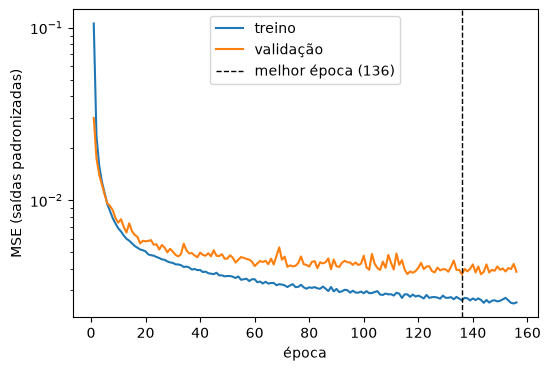

In [8]:
def grafico_MSExepoca(hist_treino, hist_val, melhor_epoca):
    plt.figure(figsize=(6, 4))
    plt.plot(range(1, len(hist_treino) + 1), hist_treino, label='treino')
    plt.plot(range(1, len(hist_val) + 1), hist_val, label='validação')
    plt.axvline(melhor_epoca, color='k', ls='--', lw=1, label=f'melhor época ({melhor_epoca})')
    plt.yscale('log')
    plt.xlabel('época'); plt.ylabel('MSE (saídas padronizadas)'); plt.legend()
    plt.show()


grafico_MSExepoca(hist_treino, hist_val, melhor_epoca)

## Estágio 2: POD-NN para o Cp

- o Cp só existe pra Re = 1e6 e alpha de 0 a 8 graus, então não tem entrada de Reynolds e só vale nessa faixa
- mesmos aerofólios de treino, validação e teste do estágio 1
- alguns aerofólios ficam sem Cp porque a limpeza do banco tirou os polares de Re = 1e6

In [9]:
d = np.load(DB / 'cp_Re1e6.npz')
cp_id, cp_alpha, x_grid, cp = d['id'], d['alpha'], d['x'], d['cp'].astype(np.float64)

m_tr = np.isin(cp_id, ids_tr)
m_val = np.isin(cp_id, ids_val)
m_te = np.isin(cp_id, ids_te)
id_naca = int(airfoils.loc[airfoils['name'] == 'naca2412', 'id'].iloc[0])
m_na = (cp_id == id_naca)

print('Curvas de Cp treino/val/teste/NACA:', m_tr.sum(), m_val.sum(), m_te.sum(), m_na.sum())
print('Aerofólios com Cp no treino:', len(np.unique(cp_id[m_tr])))

Curvas de Cp treino/val/teste/NACA: 10554 2277 2264 5
Aerofólios com Cp no treino: 2135


### Padrões (SVD)

- subtraio a curva média do treino e monto a matriz 200 x N curvas
- SVD econômica, as colunas de U são os modos POD
- fico com o menor r que chega a 99,9% da energia acumulada

r = 17 modos para 99,9 % da energia (E(r) = 0.99905)
Energia dos 4 primeiros modos (%): [82.28  9.19  3.97  1.4 ]


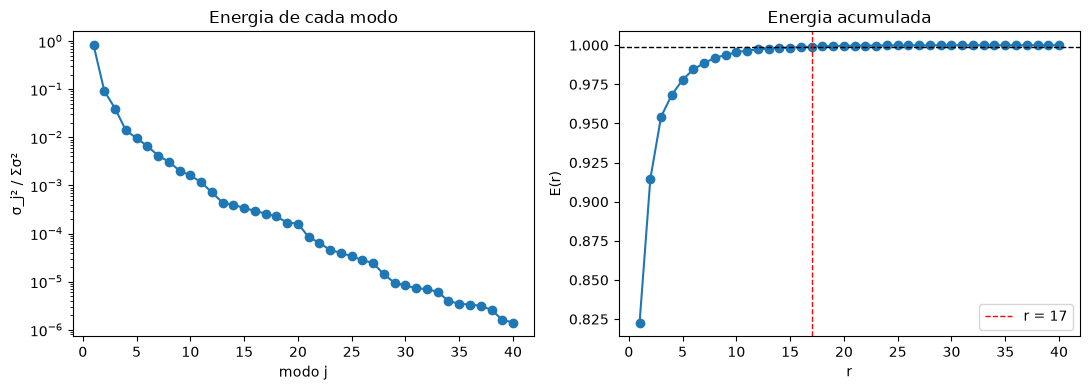

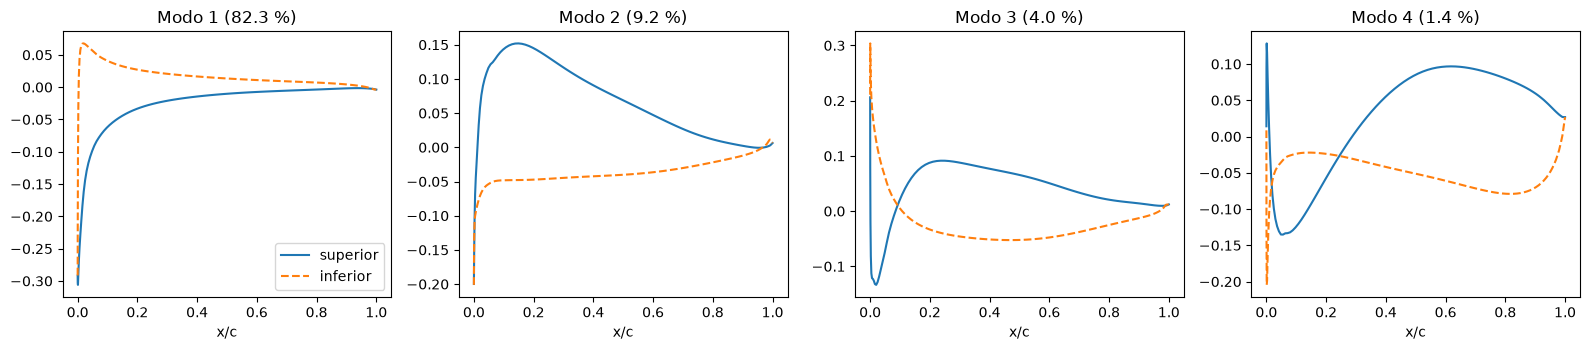

In [10]:
cp_medio = cp[m_tr].mean(axis=0)               # curva média do treino
X_snap = (cp[m_tr] - cp_medio).T               # 200 x N_treino
U, S, Vt = np.linalg.svd(X_snap, full_matrices=False)

energia = S ** 2 / np.sum(S ** 2)
energia_acum = np.cumsum(energia)
r = int(np.argmax(energia_acum >= 0.999)) + 1
Phi = U[:, :r]                                 # 200 x r

print(f'r = {r} modos para 99,9 % da energia (E(r) = {energia_acum[r - 1]:.5f})')
print('Energia dos 4 primeiros modos (%):', np.round(energia[:4] * 100, 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(np.arange(1, 41), energia[:40], 'o-')
ax[0].set_xlabel('modo j'); ax[0].set_ylabel('σ_j² / Σσ²'); ax[0].set_title('Energia de cada modo')
ax[1].plot(np.arange(1, 41), energia_acum[:40], 'o-')
ax[1].axhline(0.999, color='k', ls='--', lw=1)
ax[1].axvline(r, color='r', ls='--', lw=1, label=f'r = {r}')
ax[1].set_xlabel('r'); ax[1].set_ylabel('E(r)'); ax[1].set_title('Energia acumulada'); ax[1].legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for j in range(4):
    ax[j].plot(x_grid, Phi[:100, j], label='superior')
    ax[j].plot(x_grid, Phi[100:, j], '--', label='inferior')
    ax[j].set_title(f'Modo {j + 1} ({energia[j] * 100:.1f} %)')
    ax[j].set_xlabel('x/c')
ax[0].legend()
plt.tight_layout()
plt.show()

### Gabarito e piso de projeção

- modos ortonormais, então os coeficientes são a = Phi^T (Cp - média)
- projetar todas as curvas dá o gabarito que a rede tenta prever
- piso de projeção: erro de reconstruir o teste com os coeficientes exatos, é o melhor possível com r modos

In [11]:
A_all = (cp - cp_medio) @ Phi                  # N x r


def reconstroi(A):
    return cp_medio + A @ Phi.T


rmse_piso = np.sqrt(np.mean((reconstroi(A_all[m_te]) - cp[m_te]) ** 2))
rmse_piso_na = np.sqrt(np.mean((reconstroi(A_all[m_na]) - cp[m_na]) ** 2))
print(f'Piso de projeção (teste): RMSE de Cp = {rmse_piso:.5f}')

Piso de projeção (teste): RMSE de Cp = 0.01500


### Rede do estágio 2

- entradas: 12 CST e alpha (13, padronizadas com o treino)
- saídas: os r coeficientes divididos pelo desvio do primeiro
- padronizar cada coeficiente separado daria o mesmo peso pros modos de pouca energia, e a perda não acompanharia mais o erro da curva

In [12]:
cst = airfoils.set_index('id')[X_columns[:12]]
X_cp = np.column_stack([cst.loc[cp_id].values, cp_alpha]).astype(np.float32)

mx2, sx2 = X_cp[m_tr].mean(axis=0), X_cp[m_tr].std(axis=0)
X_cp_s = (X_cp - mx2) / sx2

escala = A_all[m_tr][:, 0].std()               # um número só pra todos os coeficientes
A_s = (A_all / escala).astype(np.float32)

E_tr, S_tr = torch.tensor(X_cp_s[m_tr]), torch.tensor(A_s[m_tr])
E_va, S_va = torch.tensor(X_cp_s[m_val]), torch.tensor(A_s[m_val])

torch.manual_seed(0)
rede2 = nn.Sequential(
    nn.Linear(13, 64), nn.Tanh(),
    nn.Linear(64, 64), nn.Tanh(),
    nn.Linear(64, r)
)
h_tr2, h_va2, melhor_epoca2, melhor_val2 = treina(
    rede2, E_tr, S_tr, E_va, S_va, batch=128, paciencia=30, max_epocas=1000)
print('Estágio 2: melhor época', melhor_epoca2, '| MSE de validação:', melhor_val2)

Parou na época 304
Estágio 2: melhor época 274 | MSE de validação: 0.00011083277786383405


### Uso e resultado

- a soma dos modos com os coeficientes previstos reconstrói o Cp
- comparo o RMSE do teste com o piso de projeção
- gráfico da NACA 2412 em 0, 4 e 8 graus

POD-NN (teste): RMSE de Cp = 0.02613 | piso = 0.01500
NACA 2412: RMSE de Cp = 0.01188 | piso = 0.00565


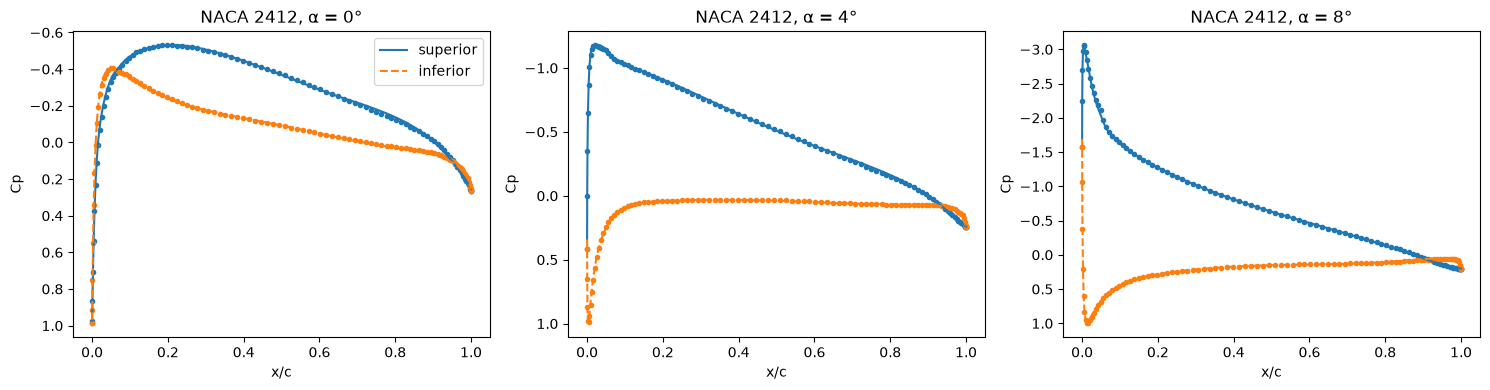

In [13]:
with torch.no_grad():
    A_prev = rede2(torch.tensor(X_cp_s)).numpy() * escala
cp_prev = reconstroi(A_prev)

rmse_pod = np.sqrt(np.mean((cp_prev[m_te] - cp[m_te]) ** 2))
rmse_pod_na = np.sqrt(np.mean((cp_prev[m_na] - cp[m_na]) ** 2))
print(f'POD-NN (teste): RMSE de Cp = {rmse_pod:.5f} | piso = {rmse_piso:.5f}')
print(f'NACA 2412: RMSE de Cp = {rmse_pod_na:.5f} | piso = {rmse_piso_na:.5f}')

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, al in enumerate([0, 4, 8]):
    i = np.where(m_na & (cp_alpha == al))[0][0]
    ax[k].plot(x_grid, cp[i, :100], 'o', ms=3, color='C0')            # XFOIL, superior
    ax[k].plot(x_grid, cp[i, 100:], 'o', ms=3, color='C1')            # XFOIL, inferior
    ax[k].plot(x_grid, cp_prev[i, :100], '-', color='C0', label='superior')
    ax[k].plot(x_grid, cp_prev[i, 100:], '--', color='C1', label='inferior')
    ax[k].invert_yaxis()                                              # convenção: Cp negativo em cima
    ax[k].set_xlabel('x/c'); ax[k].set_ylabel('Cp'); ax[k].set_title(f'NACA 2412, α = {al}°')
ax[0].legend()
plt.tight_layout()
plt.show()

## Fontes

### Bibliotecas

- PyTorch, montar a rede (nn.Sequential): <https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html>
- PyTorch, otimizador Adam: <https://pytorch.org/docs/stable/generated/torch.optim.Adam.html>
- PyTorch, DataLoader e TensorDataset: <https://pytorch.org/docs/stable/data.html>
- PyTorch, tutorial de como montar uma rede: <https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html>
- NumPy, SVD (np.linalg.svd): <https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html>
- NumPy, ajuste de reta (np.polyfit): <https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html>
- pandas, juntar tabelas (pd.merge): <https://pandas.pydata.org/docs/reference/api/pandas.merge.html>
- matplotlib, gráficos (plt.subplots): <https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html>

### Dados e ferramentas

- XFOIL: <https://web.mit.edu/drela/Public/web/xfoil/>
- UIUC Airfoil Coordinates Database: <https://m-selig.ae.illinois.edu/ads/coord_database.html>
- base da disciplina: README da pasta airfoil_db_v1_to_students

### Métodos

- Adam: Kingma e Ba (2014): <https://arxiv.org/abs/1412.6980>
- POD (Proper Orthogonal Decomposition): <https://en.wikipedia.org/wiki/Proper_orthogonal_decomposition>
- early stopping: Goodfellow et al., Deep Learning, cap. 7: <https://www.deeplearningbook.org/>
- coeficientes CST: Kulfan (2008), Universal Parametric Geometry Representation Method, Journal of Aircraft